# PA27 — Results Analysis

**Porto vs. Bragança | T3 Cold Stress | Winter Road-Service Operator**

This notebook analyses the outputs of the frozen 20-run streaming experiment:

- 2 cities
- 2 feature representations (A and B)
- 5 mandatory online classifiers
- 2016–2017 warm-up
- 2018–2025 prequential evaluation




## 1. Setup

This cell locates the project root, imports the analysis libraries, and creates dedicated output folders for report-ready tables and figures.




In [1]:
from pathlib import Path
import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


def find_project_root():
    # Find the repository root when the notebook is run from /notebooks or the project root.
    cwd = Path.cwd().resolve()

    for candidate in [cwd, *cwd.parents]:
        if (
            (candidate / "config").exists()
            and (candidate / "src").exists()
            and (candidate / "results").exists()
        ):
            return candidate

    if cwd.name == "notebooks":
        candidate = cwd.parent
        if (candidate / "config").exists() and (candidate / "src").exists():
            return candidate

    raise FileNotFoundError(
        "Could not locate the project root. "
        "Run this notebook from the repository or its notebooks/ directory."
    )


PROJECT_ROOT = find_project_root()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from config.experiment import (
    CITY_A,
    CITY_B,
    MODEL_NAMES,
    REPRESENTATIONS,
    TARGET_COLUMN,
)

RESULTS_DIR = PROJECT_ROOT / "results"
SUMMARY_PATH = RESULTS_DIR / "summaries" / "experiment_summary.csv"
HISTORY_DIR = RESULTS_DIR / "histories"
MANIFEST_PATH = RESULTS_DIR / "experiment_manifest.json"

OUTPUTS_DIR = PROJECT_ROOT / "outputs"
RESULT_TABLE_DIR = OUTPUTS_DIR / "results_tables"
RESULT_FIGURE_DIR = OUTPUTS_DIR / "results_figures"

RESULT_TABLE_DIR.mkdir(parents=True, exist_ok=True)
RESULT_FIGURE_DIR.mkdir(parents=True, exist_ok=True)

CITIES = [CITY_A, CITY_B]

MODEL_LABELS = {
    "gaussian_nb": "GaussianNB",
    "logistic_regression": "Online Logistic",
    "hoeffding_tree": "Hoeffding Tree",
    "online_bagging": "Online Bagging",
    "adaptive_random_forest": "Adaptive Random Forest",
}

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)

print("Project root:", PROJECT_ROOT)
print("Summary path:", SUMMARY_PATH)
print("History directory:", HISTORY_DIR)
print("Tables will be saved to:", RESULT_TABLE_DIR)
print("Figures will be saved to:", RESULT_FIGURE_DIR)


Project root: /Users/joaosilva/data-stream-mining-pa27
Summary path: /Users/joaosilva/data-stream-mining-pa27/results/summaries/experiment_summary.csv
History directory: /Users/joaosilva/data-stream-mining-pa27/results/histories
Tables will be saved to: /Users/joaosilva/data-stream-mining-pa27/outputs/results_tables
Figures will be saved to: /Users/joaosilva/data-stream-mining-pa27/outputs/results_figures


## 2. Load experiment outputs

The final summary contains one row per controlled experiment. The history files contain the prequential performance trajectory for each run.

**What this result shows:** this output confirms that the notebook is reading the expected experiment artefacts before any analysis is performed.




In [2]:
if not SUMMARY_PATH.exists():
    raise FileNotFoundError(
        f"Missing {SUMMARY_PATH}. Run the official experiments before this notebook."
    )

summary = pd.read_csv(SUMMARY_PATH)

history_paths = sorted(HISTORY_DIR.glob("*.csv"))

if not history_paths:
    raise FileNotFoundError(
        f"No history CSV files were found in {HISTORY_DIR}."
    )

histories = []

for path in history_paths:
    history = pd.read_csv(path)

    timestamp_col = None
    for candidate in ("timestamp", "timestamp_utc"):
        if candidate in history.columns:
            timestamp_col = candidate
            break

    if timestamp_col is None:
        raise ValueError(f"No timestamp column found in {path.name}")

    history[timestamp_col] = pd.to_datetime(
        history[timestamp_col],
        utc=True,
    )

    if timestamp_col != "timestamp":
        history = history.rename(columns={timestamp_col: "timestamp"})

    histories.append(history)

history_all = pd.concat(
    histories,
    ignore_index=True,
)

manifest = None

if MANIFEST_PATH.exists():
    with MANIFEST_PATH.open("r", encoding="utf-8") as file:
        manifest = json.load(file)

print(f"Summary rows: {len(summary)}")
print(f"History files: {len(history_paths)}")
print(f"Combined history rows: {len(history_all):,}")

display(summary.head())


Summary rows: 20
History files: 20
Combined history rows: 1,402,560


,observations_processed,events,accuracy,macro_f1,precision_positive,recall_positive,tn,fp,fn,tp,cold_starts,prediction_ms_per_event,update_ms_per_event,city,representation,model,model_params,random_seed,evaluation_metric_window_hours,cold_threshold,warmup_rows,evaluation_rows,warmup_model_updates,warmup_positive_events,warmup_negative_events,warmup_feature_builder_ready
0,70128,70128,0.926021,0.818597,0.523919,0.964493,59453,4986,202,5487,0,0.073219,0.004758,Porto,A,gaussian_nb,{},42,168,8.7,17544,70128,17520,1754,15790,True
1,70128,70128,0.984129,0.945208,0.928946,0.870979,64060,379,734,4955,0,0.003798,0.010900,Porto,A,logistic_regression,"{""learning_rate"": 0.05, ""standardize"": true}",42,168,8.7,17544,70128,17520,1754,15790,True
2,70128,70128,0.987694,0.957670,0.948680,0.896818,64163,276,587,5102,0,0.005212,0.024448,Porto,A,hoeffding_tree,"{""delta"": 1e-07, ""grace_period"": 200, ""leaf_pr...",42,168,8.7,17544,70128,17520,1754,15790,True
3,70128,70128,0.988607,0.960718,0.957009,0.899982,64209,230,569,5120,0,0.054857,0.241173,Porto,A,online_bagging,"{""n_models"": 10}",42,168,8.7,17544,70128,17520,1754,15790,True
4,70128,70128,0.978796,0.924652,0.920873,0.808051,64044,395,1092,4597,0,0.061224,0.352724,Porto,A,adaptive_random_forest,"{""delta"": 0.01, ""grace_period"": 50, ""lambda_va...",42,168,8.7,17544,70128,17520,1754,15790,True


## 3. Mechanical experiment audit

This section checks whether the saved outputs are internally consistent with the frozen experimental design.


**What this result shows:** whether all mandatory city × representation × model combinations are present, whether confusion-matrix counts match the number of evaluated observations, whether cold starts occurred, and whether key experiment metadata stayed constant.




In [3]:
key_cols = ["city", "representation", "model"]

required_summary_cols = {
    "city",
    "representation",
    "model",
    "accuracy",
    "macro_f1",
    "precision_positive",
    "recall_positive",
    "tn",
    "fp",
    "fn",
    "tp",
    "prediction_ms_per_event",
    "update_ms_per_event",
}

missing = required_summary_cols - set(summary.columns)

if missing:
    raise ValueError(
        "The experiment summary is missing required columns: "
        f"{sorted(missing)}"
    )

expected_combinations = (
    len(CITIES)
    * len(REPRESENTATIONS)
    * len(MODEL_NAMES)
)

confusion_total = (
    summary["tn"]
    + summary["fp"]
    + summary["fn"]
    + summary["tp"]
)

audit = {
    "Expected 20 experiments":
        len(summary) == expected_combinations,

    "No duplicate city/representation/model runs":
        not summary.duplicated(key_cols).any(),

    "All configured cities present":
        set(summary["city"]) == set(CITIES),

    "All configured representations present":
        set(summary["representation"]) == set(REPRESENTATIONS),

    "All configured models present":
        set(summary["model"]) == set(MODEL_NAMES),

    "Confusion-matrix totals are internally constant":
        confusion_total.nunique() == 1,

    "No cold starts":
        (
            bool((summary["cold_starts"] == 0).all())
            if "cold_starts" in summary.columns
            else True
        ),

    "Single frozen threshold":
        (
            summary["cold_threshold"].nunique() == 1
            if "cold_threshold" in summary.columns
            else True
        ),

    "Single random seed":
        (
            summary["random_seed"].nunique() == 1
            if "random_seed" in summary.columns
            else True
        ),

    "20 history files":
        len(history_paths) == expected_combinations,
}

audit_df = pd.DataFrame(
    {
        "check": list(audit.keys()),
        "passed": list(audit.values()),
    }
)

display(audit_df)

if not audit_df["passed"].all():
    raise AssertionError(
        "At least one experiment audit check failed. "
        "Do not continue to scientific interpretation until it is resolved."
    )

print(
    "Evaluated observations per run:",
    int(confusion_total.iloc[0]),
)


,check,passed
0,Expected 20 experiments,True
1,No duplicate city/representation/model runs,True
2,All configured cities present,True
3,All configured representations present,True
4,All configured models present,True
5,Confusion-matrix totals are internally constant,True
6,No cold starts,True
7,Single frozen threshold,True
8,Single random seed,True
9,20 history files,True


Evaluated observations per run: 70128


## 4. Final predictive performance

The professor requires the following predictive evidence:

- Accuracy
- Macro-F1
- Precision for the positive / event class
- Recall for the positive / event class
- Confusion Matrix

The next tables provide the first four metrics for every mandatory model and both feature representations.






In [4]:
PREDICTIVE_METRICS = [
    "accuracy",
    "macro_f1",
    "precision_positive",
    "recall_positive",
]


def predictive_table(city):
    table = (
        summary.loc[
            summary["city"].eq(city),
            ["model", "representation", *PREDICTIVE_METRICS],
        ]
        .copy()
    )

    table["model"] = pd.Categorical(
        table["model"],
        categories=MODEL_NAMES,
        ordered=True,
    )

    table["representation"] = pd.Categorical(
        table["representation"],
        categories=REPRESENTATIONS,
        ordered=True,
    )

    return (
        table
        .sort_values(["model", "representation"])
        .set_index(["model", "representation"])
    )


for city in CITIES:
    table = predictive_table(city)

    print(f"\n{city} — final predictive metrics")
    display(table.round(4))

    table.to_csv(
        RESULT_TABLE_DIR
        / f"{city.lower()}_predictive_performance.csv"
    )



Porto — final predictive metrics


accuracy  macro_f1  precision_positive  recall_positive
model                  representation                                                         
gaussian_nb            A                 0.9260    0.8186              0.5239           0.9645
                       B                 0.9357    0.8380              0.5590           0.9808
logistic_regression    A                 0.9841    0.9452              0.9289           0.8710
                       B                 0.9840    0.9448              0.9248           0.8734
hoeffding_tree         A                 0.9877    0.9577              0.9487           0.8968
                       B                 0.9876    0.9588              0.9168           0.9320
online_bagging         A                 0.9886    0.9607              0.9570           0.9000
                       B                 0.9891    0.9631              0.9419           0.9225
adaptive_random_forest A                 0.9788    0.9247              0.9209           0.8081
                       B                 0.9786    0.9234              0.9270           0.7991


Braganca — final predictive metrics


accuracy  macro_f1  precision_positive  recall_positive
model                  representation                                                         
gaussian_nb            A                 0.8237    0.8051              0.6424           0.8867
                       B                 0.8483    0.8319              0.6750           0.9219
logistic_regression    A                 0.9651    0.9577              0.9378           0.9424
                       B                 0.9681    0.9613              0.9419           0.9486
hoeffding_tree         A                 0.9616    0.9528              0.9559           0.9099
                       B                 0.9648    0.9572              0.9437           0.9347
online_bagging         A                 0.9682    0.9617              0.9350           0.9572
                       B                 0.9745    0.9692              0.9528           0.9598
adaptive_random_forest A                 0.9603    0.9516              0.9388           0.9234
                       B                 0.9598    0.9509              0.9403           0.9199

## 5. Representation A vs. Representation B

Representation B adds past-only temporal context to Representation A. The controlled comparison therefore holds the city and model constant and changes only the representation.






In [5]:
wide = summary.pivot(
    index=["city", "model"],
    columns="representation",
    values=PREDICTIVE_METRICS,
)

delta_rows = []

for city in CITIES:
    for model in MODEL_NAMES:
        row = {
            "city": city,
            "model": model,
        }

        for metric in PREDICTIVE_METRICS:
            row[f"delta_{metric}_B_minus_A"] = (
                wide.loc[(city, model), (metric, "B")]
                - wide.loc[(city, model), (metric, "A")]
            )

        delta_rows.append(row)

representation_delta = pd.DataFrame(delta_rows)

representation_delta["model"] = pd.Categorical(
    representation_delta["model"],
    categories=MODEL_NAMES,
    ordered=True,
)

representation_delta = representation_delta.sort_values(
    ["city", "model"]
)

display(
    representation_delta
    .set_index(["city", "model"])
    .round(4)
)

representation_delta.to_csv(
    RESULT_TABLE_DIR / "representation_B_minus_A_deltas.csv",
    index=False,
)


delta_accuracy_B_minus_A  delta_macro_f1_B_minus_A  delta_precision_positive_B_minus_A  delta_recall_positive_B_minus_A
city     model                                                                                                                                          
Braganca gaussian_nb                               0.0247                    0.0268                              0.0326                           0.0351
         logistic_regression                       0.0030                    0.0036                              0.0041                           0.0062
         hoeffding_tree                            0.0032                    0.0045                             -0.0122                           0.0248
         online_bagging                            0.0063                    0.0074                              0.0179                           0.0026
         adaptive_random_forest                   -0.0005                   -0.0007                              0.0015                          -0.0035
Porto    gaussian_nb                               0.0097                    0.0194                              0.0351                           0.0163
         logistic_regression                      -0.0002                   -0.0004                             -0.0041                           0.0025
         hoeffding_tree                           -0.0001                    0.0011                             -0.0319                           0.0352
         online_bagging                            0.0005                    0.0023                             -0.0152                           0.0225
         adaptive_random_forest                   -0.0002                   -0.0013                              0.0061                          -0.0090

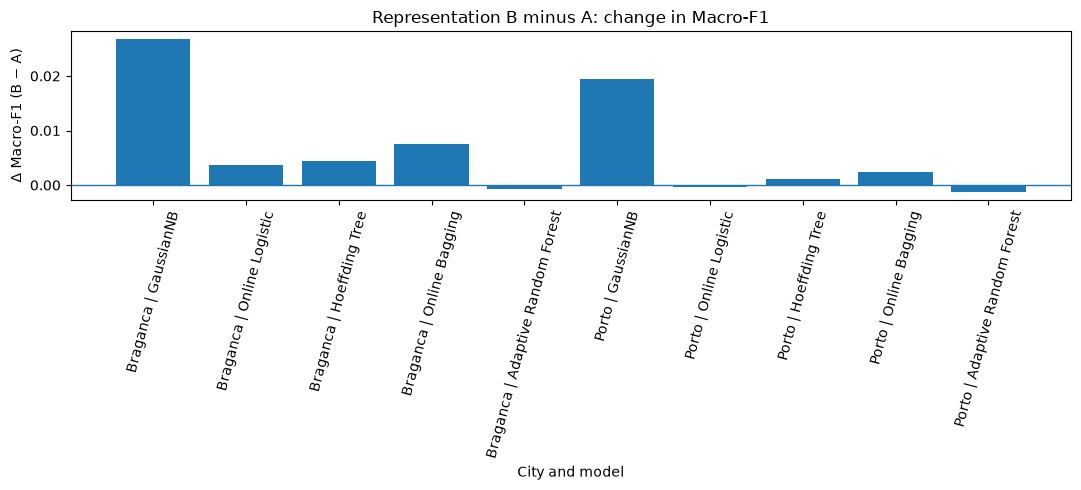

Saved: /Users/joaosilva/data-stream-mining-pa27/outputs/results_figures/representation_delta_macro_f1.png


In [6]:
# Original-analysis candidate 1:
# change in Macro-F1 from Representation A to Representation B.

plot_df = representation_delta.copy()
plot_df["label"] = (
    plot_df["city"].astype(str)
    + " | "
    + plot_df["model"].astype(str).map(MODEL_LABELS)
)

fig, ax = plt.subplots(figsize=(11, 5))

ax.bar(
    plot_df["label"],
    plot_df["delta_macro_f1_B_minus_A"],
)

ax.axhline(0, linewidth=1)
ax.set_title("Representation B minus A: change in Macro-F1")
ax.set_ylabel("Δ Macro-F1 (B − A)")
ax.set_xlabel("City and model")
ax.tick_params(axis="x", rotation=75)

fig.tight_layout()

path = RESULT_FIGURE_DIR / "representation_delta_macro_f1.png"
fig.savefig(path, dpi=200, bbox_inches="tight")
plt.show()

print("Saved:", path)


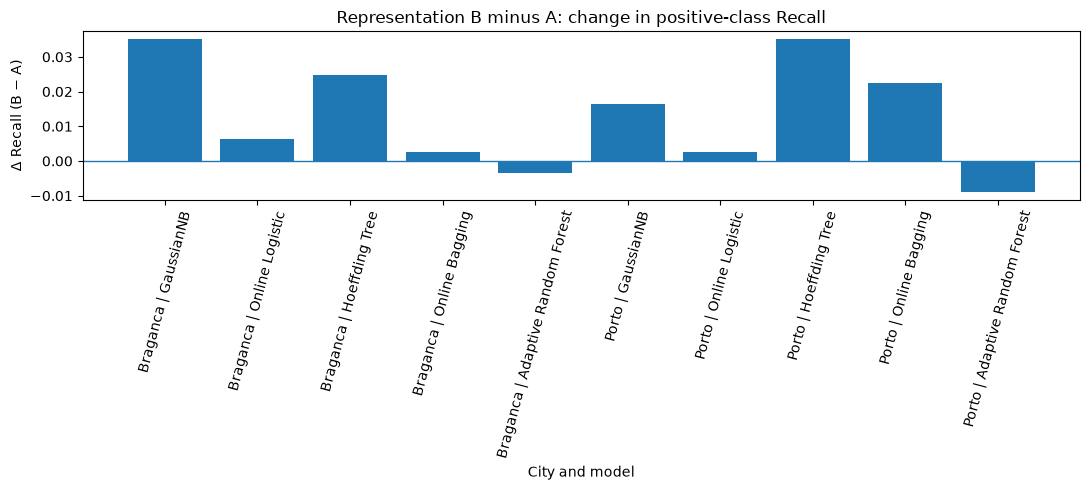

Saved: /Users/joaosilva/data-stream-mining-pa27/outputs/results_figures/representation_delta_recall.png


In [7]:
# Original-analysis candidate 2:
# change in positive-class Recall from Representation A to Representation B.

plot_df = representation_delta.copy()
plot_df["label"] = (
    plot_df["city"].astype(str)
    + " | "
    + plot_df["model"].astype(str).map(MODEL_LABELS)
)

fig, ax = plt.subplots(figsize=(11, 5))

ax.bar(
    plot_df["label"],
    plot_df["delta_recall_positive_B_minus_A"],
)

ax.axhline(0, linewidth=1)
ax.set_title("Representation B minus A: change in positive-class Recall")
ax.set_ylabel("Δ Recall (B − A)")
ax.set_xlabel("City and model")
ax.tick_params(axis="x", rotation=75)

fig.tight_layout()

path = RESULT_FIGURE_DIR / "representation_delta_recall.png"
fig.savefig(path, dpi=200, bbox_inches="tight")
plt.show()

print("Saved:", path)


## 6. Confusion-matrix evidence and event-detection errors

The complete confusion matrix is required evidence. Instead of producing 20 large heatmaps, this notebook keeps the exact TN / FP / FN / TP counts in a compact table and adds a focused FP-vs-FN plot.




In [8]:
confusion_table = (
    summary[
        [
            "city",
            "representation",
            "model",
            "tn",
            "fp",
            "fn",
            "tp",
        ]
    ]
    .copy()
)

confusion_table["model"] = pd.Categorical(
    confusion_table["model"],
    categories=MODEL_NAMES,
    ordered=True,
)

confusion_table = confusion_table.sort_values(
    ["city", "representation", "model"]
)

display(
    confusion_table
    .set_index(["city", "representation", "model"])
)

confusion_table.to_csv(
    RESULT_TABLE_DIR / "confusion_matrix_counts.csv",
    index=False,
)


tn     fp    fn     tp
city     representation model                                            
Braganca A              gaussian_nb             39693  10058  2308  18069
                        logistic_regression     48477   1274  1174  19203
                        hoeffding_tree          48895    856  1836  18541
                        online_bagging          48394   1357   872  19505
                        adaptive_random_forest  48524   1227  1560  18817
         B              gaussian_nb             40708   9043  1592  18785
                        logistic_regression     48558   1193  1047  19330
                        hoeffding_tree          48615   1136  1331  19046
                        online_bagging          48783    968   819  19558
                        adaptive_random_forest  48561   1190  1632  18745
Porto    A              gaussian_nb             59453   4986   202   5487
                        logistic_regression     64060    379   734   4955
                        hoeffding_tree          64163    276   587   5102
                        online_bagging          64209    230   569   5120
                        adaptive_random_forest  64044    395  1092   4597
         B              gaussian_nb             60037   4402   109   5580
                        logistic_regression     64035    404   720   4969
                        hoeffding_tree          63958    481   387   5302
                        online_bagging          64115    324   441   5248
                        adaptive_random_forest  64081    358  1143   4546

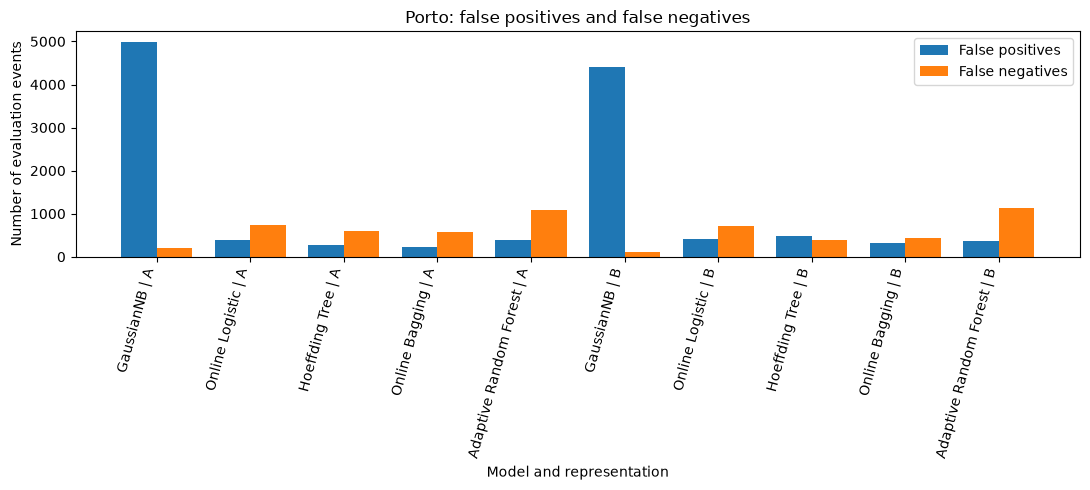

Saved: /Users/joaosilva/data-stream-mining-pa27/outputs/results_figures/porto_fp_fn_comparison.png


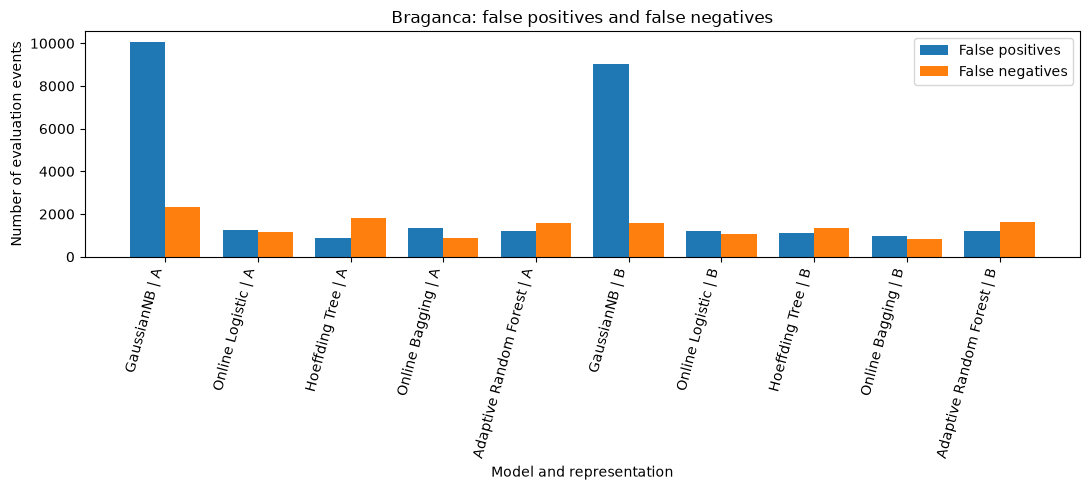

Saved: /Users/joaosilva/data-stream-mining-pa27/outputs/results_figures/braganca_fp_fn_comparison.png


In [9]:
for city in CITIES:
    plot_df = confusion_table[
        confusion_table["city"].eq(city)
    ].copy()

    plot_df["label"] = (
        plot_df["model"].astype(str).map(MODEL_LABELS)
        + " | "
        + plot_df["representation"].astype(str)
    )

    x = np.arange(len(plot_df))
    width = 0.38

    fig, ax = plt.subplots(figsize=(11, 5))

    ax.bar(
        x - width / 2,
        plot_df["fp"],
        width,
        label="False positives",
    )

    ax.bar(
        x + width / 2,
        plot_df["fn"],
        width,
        label="False negatives",
    )

    ax.set_title(f"{city}: false positives and false negatives")
    ax.set_ylabel("Number of evaluation events")
    ax.set_xlabel("Model and representation")
    ax.set_xticks(x)
    ax.set_xticklabels(
        plot_df["label"],
        rotation=75,
        ha="right",
    )
    ax.legend()

    fig.tight_layout()

    path = (
        RESULT_FIGURE_DIR
        / f"{city.lower()}_fp_fn_comparison.png"
    )

    fig.savefig(
        path,
        dpi=200,
        bbox_inches="tight",
    )

    plt.show()

    print("Saved:", path)


## 7. Model behaviour over time

Final cumulative scores can hide temporary changes in streaming performance. The histories therefore contain rolling / recent-window metrics collected during prequential evaluation.

The experiment uses a 168-hour recent window (7 days) when available in the saved history.




Available recent-window metrics: ['window_macro_f1', 'window_recall_positive', 'window_precision_positive', 'window_accuracy']


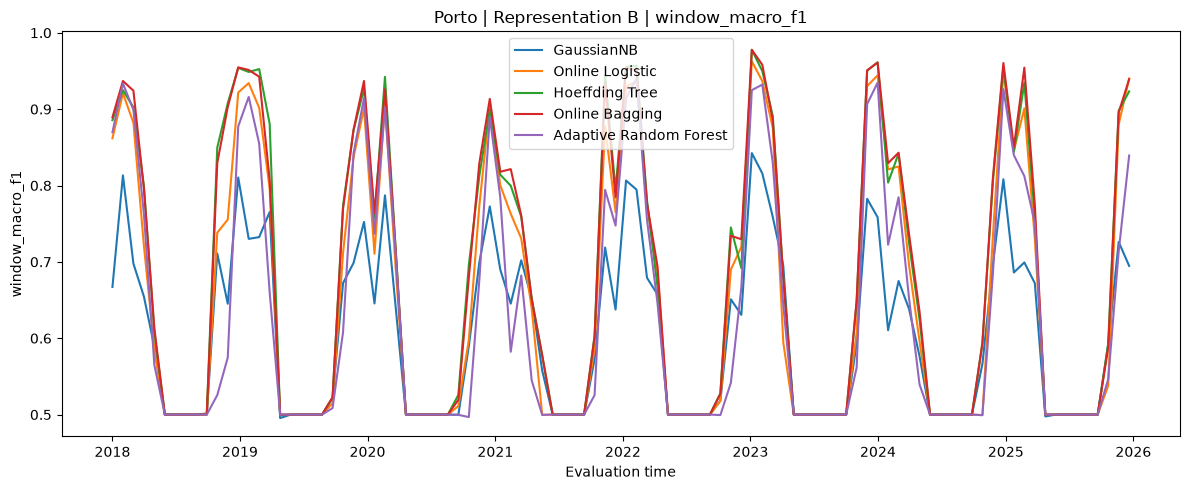

Saved: /Users/joaosilva/data-stream-mining-pa27/outputs/results_figures/porto_b_window_macro_f1_over_time.png


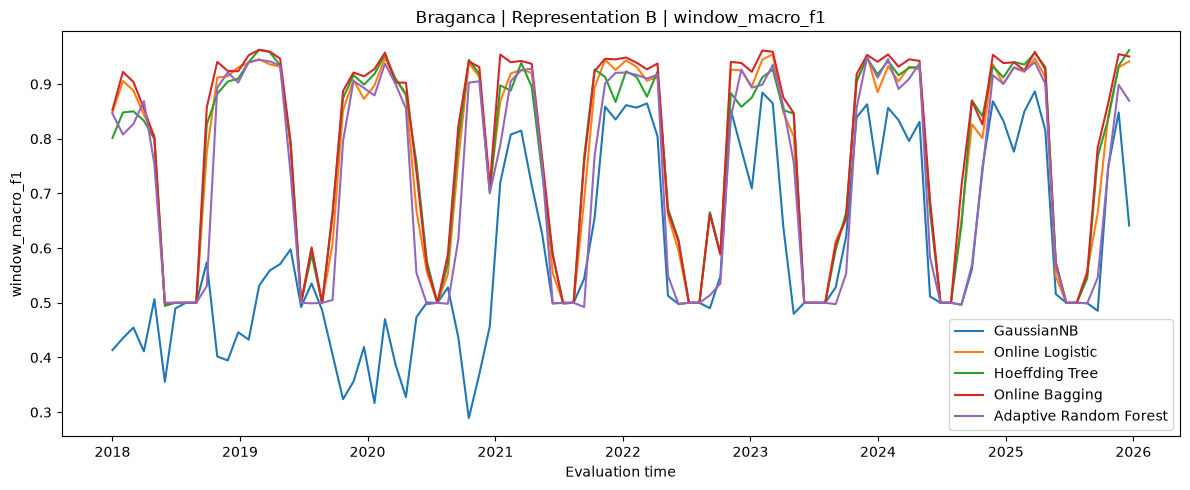

Saved: /Users/joaosilva/data-stream-mining-pa27/outputs/results_figures/braganca_b_window_macro_f1_over_time.png


In [10]:
history_metric_candidates = [
    "window_macro_f1",
    "window_recall_positive",
    "window_precision_positive",
    "window_accuracy",
]

available_history_metrics = [
    metric
    for metric in history_metric_candidates
    if metric in history_all.columns
]

print(
    "Available recent-window metrics:",
    available_history_metrics,
)


def plot_window_metric(
    city,
    representation,
    metric,
    resample_rule="30D",
):
    if metric not in history_all.columns:
        print(
            f"Skipping {metric}: column not available "
            "in the saved histories."
        )
        return

    subset = history_all[
        history_all["city"].eq(city)
        & history_all["representation"].eq(representation)
    ].copy()

    fig, ax = plt.subplots(figsize=(12, 5))

    for model in MODEL_NAMES:
        model_df = subset[
            subset["model"].eq(model)
        ].copy()

        if model_df.empty:
            continue

        model_df = (
            model_df
            .sort_values("timestamp")
            .set_index("timestamp")
        )

        # Monthly aggregation is only for visual readability.
        # The underlying hourly evaluation history remains unchanged.
        series = (
            model_df[metric]
            .resample(resample_rule)
            .mean()
        )

        ax.plot(
            series.index,
            series.values,
            label=MODEL_LABELS.get(model, model),
        )

    ax.set_title(
        f"{city} | Representation {representation} | {metric}"
    )
    ax.set_ylabel(metric)
    ax.set_xlabel("Evaluation time")
    ax.legend()

    fig.tight_layout()

    path = (
        RESULT_FIGURE_DIR
        / f"{city.lower()}_{representation.lower()}_{metric}_over_time.png"
    )

    fig.savefig(
        path,
        dpi=200,
        bbox_inches="tight",
    )

    plt.show()

    print("Saved:", path)


for city in CITIES:
    plot_window_metric(
        city=city,
        representation="B",
        metric="window_macro_f1",
    )


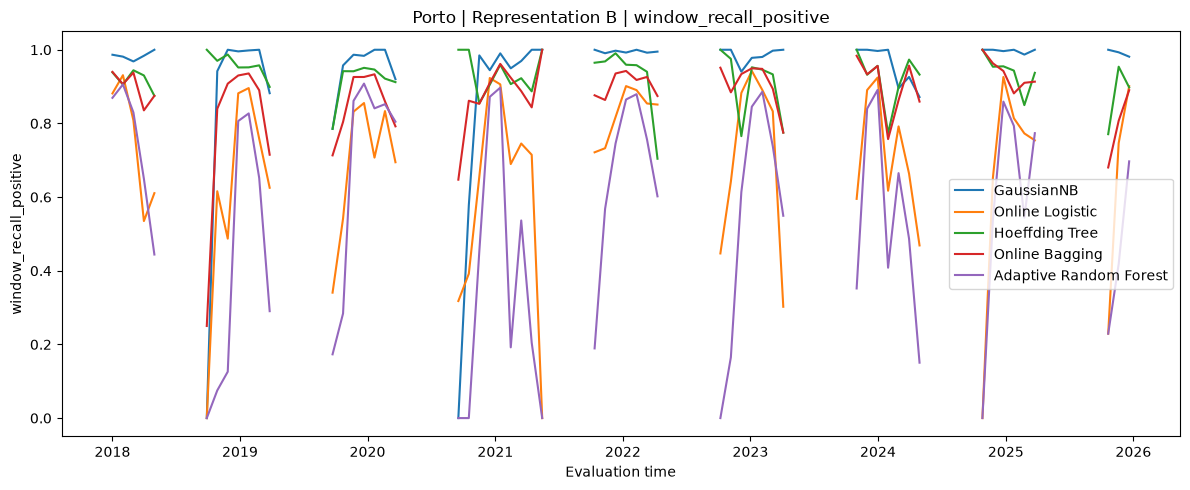

Saved: /Users/joaosilva/data-stream-mining-pa27/outputs/results_figures/porto_b_window_recall_positive_over_time.png


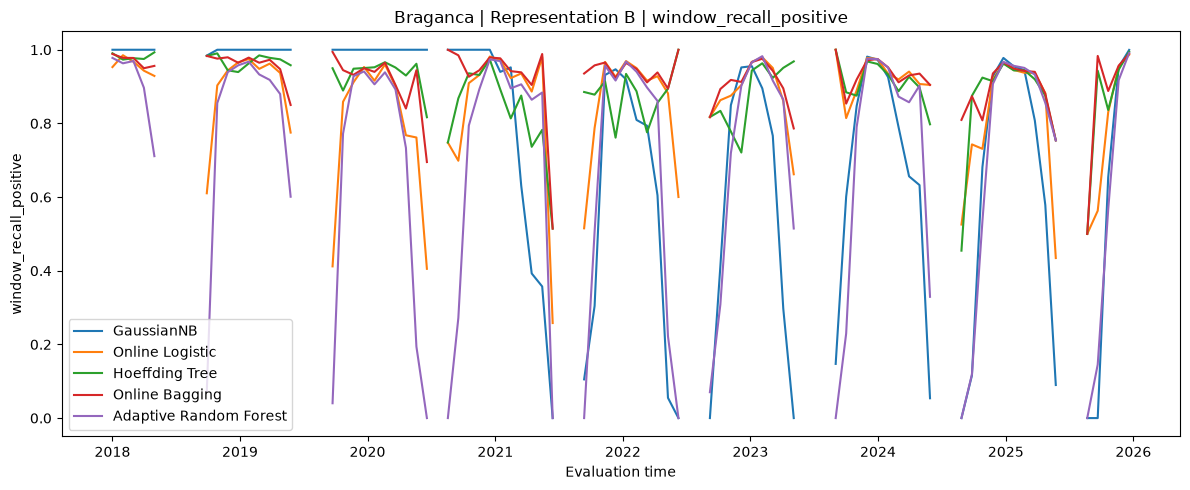

Saved: /Users/joaosilva/data-stream-mining-pa27/outputs/results_figures/braganca_b_window_recall_positive_over_time.png


In [11]:
# Optional additional temporal evidence:
# positive-class Recall over time, if this metric was stored in the histories.

if "window_recall_positive" in history_all.columns:
    for city in CITIES:
        plot_window_metric(
            city=city,
            representation="B",
            metric="window_recall_positive",
        )
else:
    print(
        "window_recall_positive is not present in the saved history files. "
        "No additional Recall-over-time plot was generated."
    )


## 8. Computational evidence and cost–performance view


The first table reports the exact measured costs from the official runs. The scatter plot places computational cost and predictive performance in the same visual space.




In [12]:
cost_table = (
    summary[
        [
            "city",
            "representation",
            "model",
            "prediction_ms_per_event",
            "update_ms_per_event",
        ]
    ]
    .copy()
)

cost_table["model"] = pd.Categorical(
    cost_table["model"],
    categories=MODEL_NAMES,
    ordered=True,
)

cost_table = cost_table.sort_values(
    ["city", "representation", "model"]
)

display(
    cost_table
    .set_index(["city", "representation", "model"])
    .round(6)
)

cost_table.to_csv(
    RESULT_TABLE_DIR / "computational_cost.csv",
    index=False,
)


prediction_ms_per_event  update_ms_per_event
city     representation model                                                               
Braganca A              gaussian_nb                            0.073208             0.005136
                        logistic_regression                    0.004071             0.012057
                        hoeffding_tree                         0.006642             0.030302
                        online_bagging                         0.064768             0.270534
                        adaptive_random_forest                 0.071614             0.433699
         B              gaussian_nb                            0.079986             0.006691
                        logistic_regression                    0.004672             0.014130
                        hoeffding_tree                         0.007236             0.033091
                        online_bagging                         0.066260             0.327225
                        adaptive_random_forest                 0.072050             0.510471
Porto    A              gaussian_nb                            0.073219             0.004758
                        logistic_regression                    0.003798             0.010900
                        hoeffding_tree                         0.005212             0.024448
                        online_bagging                         0.054857             0.241173
                        adaptive_random_forest                 0.061224             0.352724
         B              gaussian_nb                            0.078040             0.006066
                        logistic_regression                    0.004487             0.014101
                        hoeffding_tree                         0.006001             0.030812
                        online_bagging                         0.058523             0.303951
                        adaptive_random_forest                 0.063740             0.415492

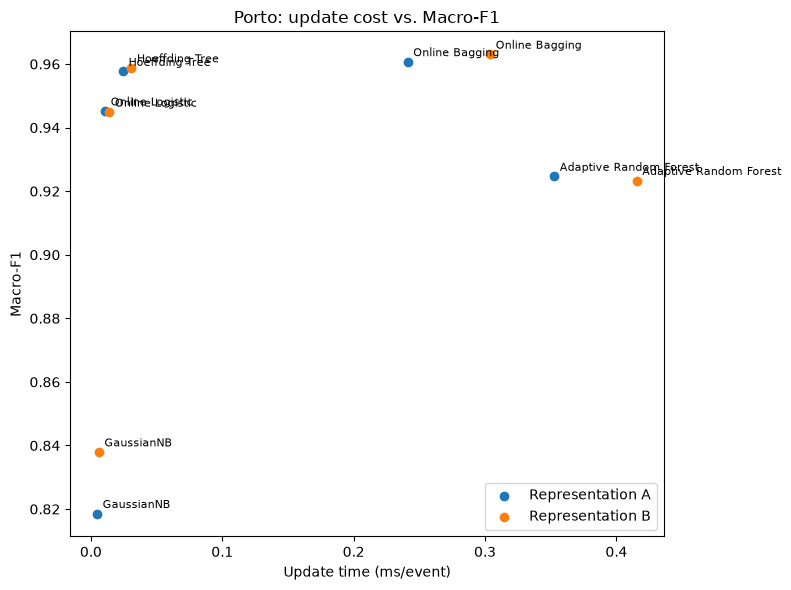

Saved: /Users/joaosilva/data-stream-mining-pa27/outputs/results_figures/porto_cost_vs_macro_f1.png


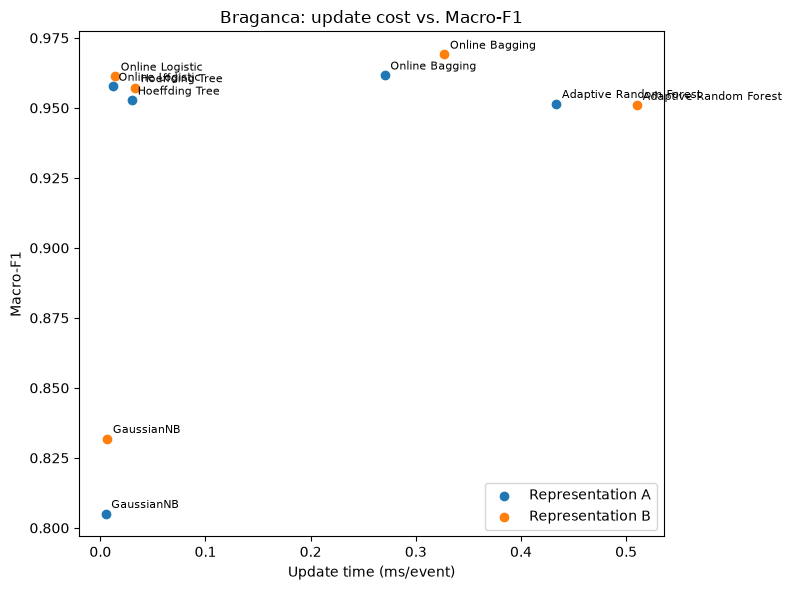

Saved: /Users/joaosilva/data-stream-mining-pa27/outputs/results_figures/braganca_cost_vs_macro_f1.png


In [13]:
for city in CITIES:
    plot_df = summary[
        summary["city"].eq(city)
    ].copy()

    fig, ax = plt.subplots(figsize=(8, 6))

    for representation in REPRESENTATIONS:
        rep_df = plot_df[
            plot_df["representation"].eq(representation)
        ]

        ax.scatter(
            rep_df["update_ms_per_event"],
            rep_df["macro_f1"],
            label=f"Representation {representation}",
        )

        for _, row in rep_df.iterrows():
            ax.annotate(
                MODEL_LABELS.get(row["model"], row["model"]),
                (
                    row["update_ms_per_event"],
                    row["macro_f1"],
                ),
                xytext=(4, 4),
                textcoords="offset points",
                fontsize=8,
            )

    ax.set_title(
        f"{city}: update cost vs. Macro-F1"
    )
    ax.set_xlabel("Update time (ms/event)")
    ax.set_ylabel("Macro-F1")
    ax.legend()

    fig.tight_layout()

    path = (
        RESULT_FIGURE_DIR
        / f"{city.lower()}_cost_vs_macro_f1.png"
    )

    fig.savefig(
        path,
        dpi=200,
        bbox_inches="tight",
    )

    plt.show()

    print("Saved:", path)


## 9. Persistence baseline

Because the target is hourly Cold Stress and the previous temperature / previous state is highly informative, a persistence baseline is useful contextual evidence.

The baseline is:

\[
\hat{y}_t = y_{t-1}
\]

It is **not** one of the five mandatory learners and does not replace any official experiment. It is only a reference that helps contextualise the difficulty of the hourly prediction task.




In [14]:
from src.run_experiments import prepare_experiment_data


def binary_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=int)
    y_pred = np.asarray(y_pred, dtype=int)

    tp = int(((y_true == 1) & (y_pred == 1)).sum())
    tn = int(((y_true == 0) & (y_pred == 0)).sum())
    fp = int(((y_true == 0) & (y_pred == 1)).sum())
    fn = int(((y_true == 1) & (y_pred == 0)).sum())

    accuracy = (tp + tn) / len(y_true)

    precision_positive = (
        tp / (tp + fp)
        if (tp + fp) > 0
        else np.nan
    )

    recall_positive = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else np.nan
    )

    precision_negative = (
        tn / (tn + fn)
        if (tn + fn) > 0
        else np.nan
    )

    recall_negative = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    f1_positive = (
        2
        * precision_positive
        * recall_positive
        / (precision_positive + recall_positive)
        if (
            np.isfinite(precision_positive)
            and np.isfinite(recall_positive)
            and (precision_positive + recall_positive) > 0
        )
        else np.nan
    )

    f1_negative = (
        2
        * precision_negative
        * recall_negative
        / (precision_negative + recall_negative)
        if (
            np.isfinite(precision_negative)
            and np.isfinite(recall_negative)
            and (precision_negative + recall_negative) > 0
        )
        else np.nan
    )

    macro_f1 = np.nanmean(
        [f1_negative, f1_positive]
    )

    return {
        "accuracy": accuracy,
        "macro_f1": macro_f1,
        "precision_positive": precision_positive,
        "recall_positive": recall_positive,
        "tn": tn,
        "fp": fp,
        "fn": fn,
        "tp": tp,
    }


city_streams, threshold = prepare_experiment_data()

baseline_rows = []

for city in CITIES:
    warmup = city_streams[city]["warmup"]
    evaluation = city_streams[city]["evaluation"]

    y_true = (
        evaluation[TARGET_COLUMN]
        .astype(int)
        .reset_index(drop=True)
    )

    previous_state = np.empty(
        len(evaluation),
        dtype=int,
    )

    previous_state[0] = int(
        warmup[TARGET_COLUMN].iloc[-1]
    )

    previous_state[1:] = (
        y_true.iloc[:-1]
        .to_numpy(dtype=int)
    )

    metrics = binary_metrics(
        y_true,
        previous_state,
    )

    baseline_rows.append(
        {
            "city": city,
            "baseline": "persistence_y_t_minus_1",
            **metrics,
        }
    )

persistence_baseline = pd.DataFrame(
    baseline_rows
)

display(
    persistence_baseline
    .set_index(["city", "baseline"])
    .round(4)
)

persistence_baseline.to_csv(
    RESULT_TABLE_DIR / "persistence_baseline.csv",
    index=False,
)


,,accuracy,macro_f1,precision_positive,recall_positive,tn,fp,fn,tp
city,baseline,,,,,,,,
Porto,persistence_y_t_minus_1,0.9829,0.9426,0.8945,0.8944,63839,600,601,5088
Braganca,persistence_y_t_minus_1,0.9636,0.9558,0.9373,0.9373,48473,1278,1278,19099


## 10. Transition diagnostics

Persistence is strongest when the target remains unchanged. Therefore, a useful supplementary diagnostic is to inspect the hours where the Cold Stress state changes:

- `0 → 1`: Cold Stress onset
- `1 → 0`: Cold Stress ending




In [15]:
transition_rows = []

for path in history_paths:
    history = pd.read_csv(path)

    timestamp_col = (
        "timestamp"
        if "timestamp" in history.columns
        else "timestamp_utc"
    )

    history[timestamp_col] = pd.to_datetime(
        history[timestamp_col],
        utc=True,
    )

    history = history.sort_values(
        timestamp_col
    ).reset_index(drop=True)

    required = {
        "city",
        "representation",
        "model",
        "y_true",
        "y_pred",
    }

    if not required.issubset(history.columns):
        raise ValueError(
            f"{path.name} is missing metadata or prediction columns."
        )

    city = history["city"].iloc[0]
    representation = history["representation"].iloc[0]
    model = history["model"].iloc[0]

    y_true = history["y_true"].astype(int)
    y_pred = history["y_pred"].astype(int)

    previous = y_true.shift(1)

    # The first evaluation event uses the final warm-up state as y_(t-1).
    previous.iloc[0] = int(
        city_streams[city]["warmup"][TARGET_COLUMN].iloc[-1]
    )

    previous = previous.astype(int)

    transition_mask = y_true.ne(previous)
    onset_mask = previous.eq(0) & y_true.eq(1)
    ending_mask = previous.eq(1) & y_true.eq(0)

    transition_accuracy = (
        y_pred[transition_mask]
        .eq(y_true[transition_mask])
        .mean()
    )

    onset_detection_rate = (
        y_pred[onset_mask]
        .eq(1)
        .mean()
    )

    ending_detection_rate = (
        y_pred[ending_mask]
        .eq(0)
        .mean()
    )

    transition_rows.append(
        {
            "city": city,
            "representation": representation,
            "model": model,
            "transition_events": int(transition_mask.sum()),
            "cold_onsets_0_to_1": int(onset_mask.sum()),
            "cold_endings_1_to_0": int(ending_mask.sum()),
            "transition_accuracy": transition_accuracy,
            "onset_detection_rate": onset_detection_rate,
            "ending_detection_rate": ending_detection_rate,
        }
    )

transition_diagnostics = pd.DataFrame(
    transition_rows
)

transition_diagnostics["model"] = pd.Categorical(
    transition_diagnostics["model"],
    categories=MODEL_NAMES,
    ordered=True,
)

transition_diagnostics = transition_diagnostics.sort_values(
    ["city", "representation", "model"]
)

display(
    transition_diagnostics
    .set_index(["city", "representation", "model"])
    .round(4)
)

transition_diagnostics.to_csv(
    RESULT_TABLE_DIR / "transition_diagnostics.csv",
    index=False,
)


transition_events  cold_onsets_0_to_1  cold_endings_1_to_0  transition_accuracy  onset_detection_rate  \
city     representation model                                                                                                                           
Braganca A              gaussian_nb                          2556                1278                 1278               0.4765                0.5313   
                        logistic_regression                  2556                1278                 1278               0.3341                0.3271   
                        hoeffding_tree                       2556                1278                 1278               0.2977                0.1362   
                        online_bagging                       2556                1278                 1278               0.3838                0.4413   
                        adaptive_random_forest               2556                1278                 1278               0.2281                0.2105   
         B              gaussian_nb                          2556                1278                 1278               0.4534                0.5892   
                        logistic_regression                  2556                1278                 1278               0.4487                0.4351   
                        hoeffding_tree                       2556                1278                 1278               0.4785                0.3936   
                        online_bagging                       2556                1278                 1278               0.4840                0.4624   
                        adaptive_random_forest               2556                1278                 1278               0.2778                0.2363   
Porto    A              gaussian_nb                          1201                 601                  600               0.6711                0.9168   
                        logistic_regression                  1201                 601                  600               0.4263                0.2579   
                        hoeffding_tree                       1201                 601                  600               0.4513                0.2346   
                        online_bagging                       1201                 601                  600               0.4555                0.2146   
                        adaptive_random_forest               1201                 601                  600               0.3214                0.1597   
         B              gaussian_nb                          1201                 601                  600               0.6261                0.9468   
                        logistic_regression                  1201                 601                  600               0.4138                0.2429   
                        hoeffding_tree                       1201                 601                  600               0.6137                0.5657   
                        online_bagging                       1201                 601                  600               0.5087                0.3760   
                        adaptive_random_forest               1201                 601                  600               0.3047                0.1215   

                                                ending_detection_rate  
city     representation model                                          
Braganca A              gaussian_nb                            0.4218  
                        logistic_regression                    0.3412  
                        hoeffding_tree                         0.4593  
                        online_bagging                         0.3263  
                        adaptive_random_forest                 0.2457  
         B              gaussian_nb                            0.3177  
                        logistic_regression                    0.4624  
                        hoeffding

In [16]:
print("Generated result tables:")
for path in sorted(RESULT_TABLE_DIR.glob("*.csv")):
    print(" -", path.relative_to(PROJECT_ROOT))

print("\nGenerated result figures:")
for path in sorted(RESULT_FIGURE_DIR.glob("*.png")):
    print(" -", path.relative_to(PROJECT_ROOT))


Generated result tables:
 - outputs/results_tables/braganca_predictive_performance.csv
 - outputs/results_tables/computational_cost.csv
 - outputs/results_tables/confusion_matrix_counts.csv
 - outputs/results_tables/persistence_baseline.csv
 - outputs/results_tables/porto_predictive_performance.csv
 - outputs/results_tables/representation_B_minus_A_deltas.csv
 - outputs/results_tables/transition_diagnostics.csv

Generated result figures:
 - outputs/results_figures/braganca_b_window_macro_f1_over_time.png
 - outputs/results_figures/braganca_b_window_recall_positive_over_time.png
 - outputs/results_figures/braganca_cost_vs_macro_f1.png
 - outputs/results_figures/braganca_fp_fn_comparison.png
 - outputs/results_figures/porto_b_window_macro_f1_over_time.png
 - outputs/results_figures/porto_b_window_recall_positive_over_time.png
 - outputs/results_figures/porto_cost_vs_macro_f1.png
 - outputs/results_figures/porto_fp_fn_comparison.png
 - outputs/results_figures/representation_delta_macro_f1

### Experiment validation

The mechanical audit confirmed that the experimental outputs were internally consistent with the predefined design. All 20 expected city–representation–model combinations were present, no duplicated runs or cold starts were detected, the confusion-matrix totals matched the number of evaluation observations, and the frozen experimental settings remained consistent across runs. This provides confidence that the subsequent comparisons are based on the intended prequential evaluation protocol and on comparable evaluation histories.

### Predictive performance

Overall, the streaming classifiers achieved strong predictive performance, although the results should not be interpreted through Accuracy alone. Most models obtained high Accuracy values, indicating that the majority of hourly Cold Stress states were classified correctly. Gaussian Naive Bayes was the main exception, particularly in Bragança, where its Accuracy was noticeably lower than that of the other learners.

Positive-class Recall was generally high across the experiments, meaning that most actual Cold Stress events were successfully detected. This metric is particularly relevant in the present operational context because a false negative corresponds to a Cold Stress event that the monitoring system fails to identify. Precision was also high for most models, indicating that predictions of Cold Stress were usually correct. However, Gaussian Naive Bayes behaved differently, especially in Porto, where its very high Recall was accompanied by substantially lower Precision. Therefore, its ability to detect almost all Cold Stress events came at the cost of generating considerably more false alarms.

The resulting Macro-F1 scores were also high for most models, showing that the classifiers generally maintained a good balance between performance on the Cold Stress and non-Cold Stress classes rather than simply exploiting the majority class.

The comparison between the cities requires some nuance. Accuracy was systematically higher in Porto, while positive-class Recall was higher in Bragança for most model configurations. Precision was also generally strong in Bragança. One plausible factor is the difference in target prevalence: Cold Stress represents approximately 29% of the evaluation observations in Bragança but only about 8% in Porto. The models therefore receive substantially more positive examples in the Bragança stream, whereas the much stronger class imbalance in Porto makes high overall Accuracy easier to obtain through correct classification of the dominant non-Cold-Stress class.

### Representation A versus Representation B

The comparison between Representation A and Representation B shows that the additional temporal context introduced in Representation B does not produce a dramatic improvement in final predictive performance.

For most model–city combinations, the differences in Accuracy and Macro-F1 are relatively small. Representation B produces improvements in several cases, particularly in positive-class Recall, but these improvements are not universal. Some configurations remain almost unchanged, while Adaptive Random Forest shows small decreases in several metrics.

A plausible explanation is that the most informative temporal predictor is already available in Representation A: the previous hourly temperature, \(T_{t-1}\). Because hourly temperature is highly persistent, this single lag already contains substantial information about whether the next observation will fall below the Cold Stress threshold. The additional delta, rolling mean, rolling standard deviation and recent-condition features included in Representation B therefore provide useful temporal information in some cases, but their incremental contribution is relatively limited compared with the information already contained in the most recent temperature observation.

This suggests that the comparison between A and B is less about a dramatic change in overall predictive capability and more about whether additional temporal context can improve specific aspects of event detection, such as Recall, for particular learners.

### Cold Stress detection and false negatives

If the objective is defined strictly as maximising Cold Stress Recall and minimising false negatives, different models emerge in the two cities.

In Porto, Gaussian Naive Bayes with Representation B achieved the highest Recall, approximately 0.981, with only 109 false negatives. This means that it missed very few actual Cold Stress observations. However, this result should be considered together with its substantially lower Precision and its 4,402 false positives. The model therefore achieves extremely high event sensitivity by predicting Cold Stress relatively aggressively, generating many false alarms in the process. For this reason, Gaussian Naive Bayes B should not be considered the best overall model for Porto solely on the basis of Recall. When predictive performance, event detection and computational efficiency are considered jointly, the Hoeffding Tree with Representation B provides a more balanced solution. It maintains high Accuracy, Macro-F1, Precision and Recall while requiring substantially less update time than the ensemble approaches. Therefore, although Gaussian Naive Bayes B is preferable when the sole objective is to minimise missed Cold Stress events, Hoeffding Tree B is considered the strongest overall streaming model for Porto.

In Bragança, Online Bagging with Representation B achieved the highest Recall, approximately 0.960, and the lowest number of false negatives, with 819 missed events. Unlike Gaussian Naive Bayes in Porto, this high Recall was accompanied by high Precision, approximately 0.953, and a high Macro-F1 of approximately 0.969. Its event-detection performance is therefore substantially more balanced between missed Cold Stress events and false alarms.

These results illustrate why Recall cannot be interpreted independently from Precision and the confusion matrix. Maximising Recall alone may be desirable when missing a Cold Stress event is particularly costly, but the operational consequences of false alarms must also be considered.

### Recent-window behaviour over time

The temporal performance plots use a rolling evaluation window of 168 hours, corresponding to one week of hourly observations. They therefore describe recent model behaviour rather than cumulative performance over the complete 2018–2025 evaluation period.

A noticeable characteristic of these plots is that Macro-F1 can fall sharply during periods with few or no Cold Stress events. This behaviour is partly a consequence of the metric itself rather than evidence of a sudden deterioration of the classifier.

Macro-F1 calculates the F1-score independently for each class and then gives both classes equal weight. When a 168-hour window contains no positive Cold Stress observations, the positive class cannot obtain a meaningful positive-class F1 and is assigned an F1-score of zero by the implemented metric. If the model simultaneously classifies the non-Cold-Stress class almost perfectly, its negative-class F1 may remain close to 1. The resulting Macro-F1 is consequently close to:

\[
\frac{1 + 0}{2} = 0.5.
\]

Therefore, temporary drops towards approximately 0.5 should not automatically be interpreted as a collapse in predictive ability. They may instead reflect periods in which one of the two classes is absent from the recent evaluation window. This effect is expected to be more visible in Porto because Cold Stress events are substantially less frequent there.

The rolling plots are nevertheless useful because they show that final cumulative metrics alone do not fully describe the behaviour of an online classifier. Stream performance varies over time as the local class distribution and weather conditions change.

### Computational performance

Prediction latency was extremely low for all evaluated models, remaining below approximately 0.08 ms per event. At an hourly sampling frequency, these prediction costs are operationally negligible.

Update times showed much clearer differences between algorithms. All remained below approximately 0.6 ms per event, but update cost generally increased with model complexity. Simpler incremental learners required relatively little computation to incorporate each new observation, whereas ensemble approaches such as Online Bagging and Adaptive Random Forest required substantially more update time because several component models must be updated for each incoming event.

The Hoeffding Tree provides a particularly attractive predictive–computational trade-off. It achieves high Macro-F1 while maintaining a substantially lower update cost than the ensemble models. Online Bagging can provide stronger predictive performance in several configurations, but this improvement comes with a significantly greater computational requirement.

For this reason, the Hoeffding Tree can be considered a strong efficiency-oriented candidate when computational simplicity and continuous low-cost updating are important. This should be described as a favourable trade-off rather than as a mathematically defined “best ratio”, unless a formal cost-performance ratio is explicitly introduced.

### Persistence baseline and difficulty of the hourly prediction problem

The persistence baseline provides important context for understanding the apparently very high predictive scores obtained by the machine-learning models.

The baseline makes the simple prediction:

\[
\hat{y}_t = y_{t-1},
\]

meaning that it assumes the current Cold Stress state will be identical to the state observed one hour earlier. Despite requiring no learning algorithm, this rule achieved an Accuracy of approximately 98.3% in Porto and 96.4% in Bragança.

This demonstrates that the hourly target has very strong temporal persistence. Temperature normally changes gradually from one hour to the next, so if the temperature is already below the Cold Stress threshold at one observation, there is a high probability that it will remain below the threshold during the following observation. Similarly, a non-Cold-Stress state usually remains unchanged over consecutive hours.

The machine-learning models do not directly receive \(y_{t-1}\) as their principal predictor. However, Representation A already contains \(T_{t-1}\), and the previous Cold Stress state is itself determined by whether \(T_{t-1}\) lies below the frozen threshold. The strong persistence demonstrated by the baseline therefore helps explain why previous temperature is such a powerful predictor and why very high overall Accuracy can be achieved in this hourly forecasting setup.

Consequently, the absolute level of Accuracy should not be viewed as the most challenging aspect of the task. A more demanding problem occurs when the Cold Stress state changes between consecutive observations.

### Transition analysis

The transition analysis isolates the observations for which:

\[
y_t \neq y_{t-1}.
\]

These correspond to the onset of Cold Stress (`0 → 1`) and the end of a Cold Stress period (`1 → 0`). They are particularly informative because the persistence baseline necessarily fails on every such observation: copying the previous state cannot correctly predict a state transition.

The transition results therefore provide a stricter test of whether the classifiers can detect changes in weather regime rather than simply exploiting hourly persistence.

According to the transition diagnostic, Gaussian Naive Bayes achieved the highest transition accuracy in Porto, while Online Bagging with Representation B achieved the highest transition accuracy in Bragança. These results indicate that the models differ not only in their overall event-detection performance but also in their ability to identify the relatively uncommon moments when the Cold Stress state changes.

This transition-focused analysis is particularly useful for contextualising the very high global Accuracy values. A classifier may obtain excellent overall performance because most consecutive observations remain in the same state, while transition events represent the more difficult subset of the stream. Evaluating these cases separately therefore provides additional information about the models' ability to anticipate changes rather than simply maintain the previous classification.